# 第6回：数値微分

[講義スライド](slide.pdf) ｜ [2026年度の資料一覧](../README.md)

このノートブックは Google Colab でも実行できます。GitHub から開いた後、**「ドライブにコピーを保存」**してください。

## 浮動小数点数と丸め誤差

コンピューターは有限個のビットで実数を近似するため、多くの小数は正確には表せません。Python の `float` は通常 IEEE 754 の倍精度浮動小数点数です。

In [1]:
a = 0.1
print(f"{a:.55f}")

0.1000000000000000055511151231257827021181583404541015625


同じ小さな数を何度も足すと、丸め誤差が積み重なります。組み込み関数 `sum` を変数名に使わず、`math.fsum` と比べてみます。

In [2]:
import math

n = 10_000_000
running_total = 0.0
for _ in range(n):
    running_total += 0.01
print("通常の加算:", running_total)
print("math.fsum:", math.fsum(0.01 for _ in range(n)))

通常の加算: 99999.99998630969
math.fsum: 100000.0


## 有限差分による数値微分

テイラー展開から、前進差分・後退差分は $O(h)$、中心差分は $O(h^2)$ の打ち切り誤差を持ちます。

$$
f'(x) \approx \frac{f(x+h)-f(x)}{h},\qquad
f'(x) \approx \frac{f(x)-f(x-h)}{h},\qquad
f'(x) \approx \frac{f(x+h)-f(x-h)}{2h}.
$$

二階微分も対称な点から

$$
f''(x)\approx\frac{f(x+h)-2f(x)+f(x-h)}{h^2}+O(h^2)
$$

と近似できます。$h$ を小さくすると打ち切り誤差は減りますが、差の桁落ちが強くなります。

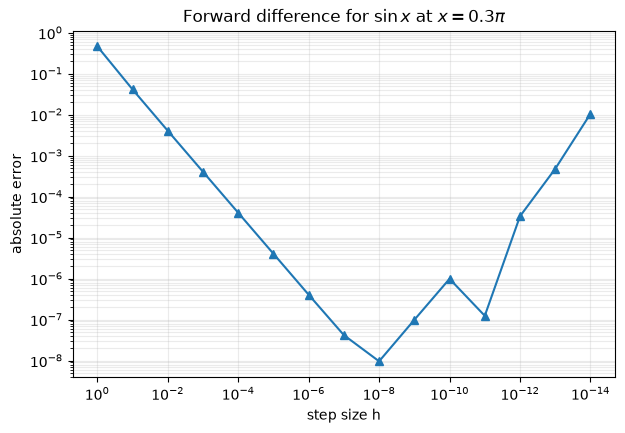

In [3]:
import numpy as np
import matplotlib.pyplot as plt

h_values = 10.0 ** (-np.arange(0, 15))  # 1 から 1e-14
x0 = 0.3 * np.pi
approximation = []
for h in h_values:
    approximation.append((np.sin(x0 + h) - np.sin(x0)) / h)
approximation = np.array(approximation)
error = np.abs(approximation - np.cos(x0))

plt.figure(figsize=(7, 4.5))
plt.loglog(h_values, error, marker="^")
plt.gca().invert_xaxis()
plt.xlabel("step size h")
plt.ylabel("absolute error")
plt.title(r"Forward difference for $\sin x$ at $x=0.3\pi$")
plt.grid(True, which="both", alpha=0.25)
plt.show()

In [4]:
# Moderate h reduces the forward-difference error for this example.
assert error[3] < error[0]
print("h =", h_values[3])
print("error =", error[3])

h = 0.001
error = 0.0004046064277518635


## 関数の変化の速さと $h$

関数が速く変化すると、差分公式の誤差の係数が大きくなります。演習で振動数を変え、誤差が小さくなる $h$ の範囲を比べてください。

## 演習

1. $f(x)=x^3-2x+1$ を $x=0.7$ で数値微分し、解析解と比較してください。前進差分と中心差分で、誤差が $h$ とともにどう変化するかを調べます。
2. $f(x)=\sin(10^4x)$ の数値微分を計算し、通常の $\sin x$ の場合と誤差が小さくなる $h$ の範囲を比べます。
3. 前進差分・後退差分・中心差分を同じグラフに描き、$h$ を極端に小さくしたときの桁落ちを確認します。

In [ ]:
# 1. ここに演習のコードを書く


In [ ]:
# 2. ここに演習のコードを書く


In [ ]:
# 3. ここに演習のコードを書く
